# Week 4: Machine Learning Model Development and Evaluation
Project Title and Objective

Bank Marketing Subscription Prediction Using Machine Learning

The objective of this project is to develop and evaluate a machine learning model that predicts whether a customer will subscribe to a term deposit based on customer information.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data Loading and Initial Inspection
df = pd.read_csv("../../data/bank-full.csv", sep=",")

# display the dataset shape
print("dataset shape: ",df.shape)

# Display the column names
df.columns.tolist()

# data information
df.info()

# check missing values
df.isnull().sum()



dataset shape:  (45211, 17)
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Subscription counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Subscription percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


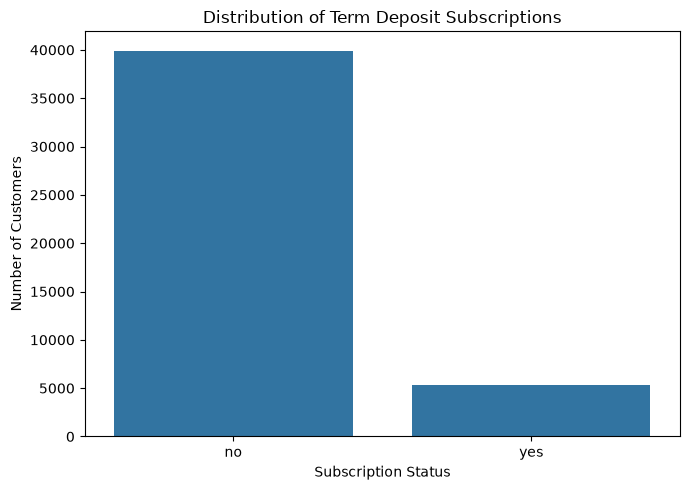

In [14]:
# Count the target categories
print("Subscription counts:")
print(df["y"].value_counts())

# Calculate percentages
print("\nSubscription percentages:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

# Visualize the target distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y")

plt.title("Distribution of Term Deposit Subscriptions")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")

plt.savefig("../charts/target_distribution.png", dpi=300, bbox_inches="tight")

plt.tight_layout()
plt.show()

##  Feature and Target Separation

The dataset contains customer information that can help predict term deposit subscriptions.

- Features (X): Customer information used to make predictions.
- Target (y): The subscription status we want to predict.


In [15]:
# Separate features and target
X = df.drop("y", axis=1)
y = df["y"]

# Display the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Display the first five feature rows
display(X.head())

Features shape: (45211, 16)
Target shape: (45211,)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown


##  Splitting the Dataset

We split the dataset into training and testing sets using an 80:20 ratio.

- Training set (80%): Used to train the machine learning model.
- Testing set (20%): Used to evaluate the model on unseen data.

In [16]:
# Import the function for splitting data
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the sizes of the datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check the target distribution in each set
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (36168, 16)
Testing features: (9043, 16)

Training target: (36168,)
Testing target: (9043,)

Training target distribution:
y
no     0.883
yes    0.117
Name: proportion, dtype: float64

Testing target distribution:
y
no     0.883
yes    0.117
Name: proportion, dtype: float64


# Data Preprocessing

Data preprocessing prepares raw data for machine learning.
The Bank Marketing dataset contains two types of features:

Numerical features: Values such as age, balance, and campaign.
Categorical features: Values such as job, education, and marital status.

We use StandardScaler to standardize numerical features and OneHotEncoder to convert categorical features into numerical representations.

A ColumnTransformer applies the appropriate transformation to each feature type. These transformations will be included in a machine learning pipeline to help prevent data leakage between the training and testing sets.

In [17]:
# Import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Create the preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Create the machine learning pipeline
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]
)

# Display the identified features
print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

print("\nPreprocessing and model pipeline created successfully.")

Numerical features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Preprocessing and model pipeline created successfully.


C:\Users\muham\AppData\Local\Temp\ipykernel_15248\2993423728.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


## Model Training

Logistic Regression learns patterns from the training data to predict whether a customer will subscribe to a term deposit.

The preprocessing pipeline transforms the features before training the model.


In [18]:
# Train the Logistic Regression model
model.fit(X_train,y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


##  Model Training

Logistic Regression learns patterns from the training data to predict whether a customer will subscribe to a term deposit.

The preprocessing pipeline transforms the features before training the model.


In [19]:
# predict subscription
y_pred = model.predict(X_test)

# display first 10 predictions
print("predicted values: ")
print(y_pred[:10])

print("\n Actual values: ")
print(y_test.iloc[:10].values)

predicted values: 
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

 Actual values: 
<StringArray>
['no', 'no', 'no', 'no', 'no', 'no', 'no', 'yes', 'no', 'no']
Length: 10, dtype: str


##  Model Evaluation

Evaluate the model using accuracy, precision, recall, and F1-score to understand its predictive performance.


In [20]:
# import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report

# calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("model accuracy: ", round(accuracy * 100,2), "%")

# display precision,recall and f1 score
print("\n classification report: ")
print(classification_report(y_test,y_pred))

model accuracy:  84.57 %

 classification report: 
              precision    recall  f1-score   support

          no       0.97      0.85      0.91      7985
         yes       0.42      0.81      0.55      1058

    accuracy                           0.85      9043
   macro avg       0.70      0.83      0.73      9043
weighted avg       0.91      0.85      0.87      9043



##  Confusion Matrix

A confusion matrix compares actual and predicted classes to show correct predictions and classification errors.


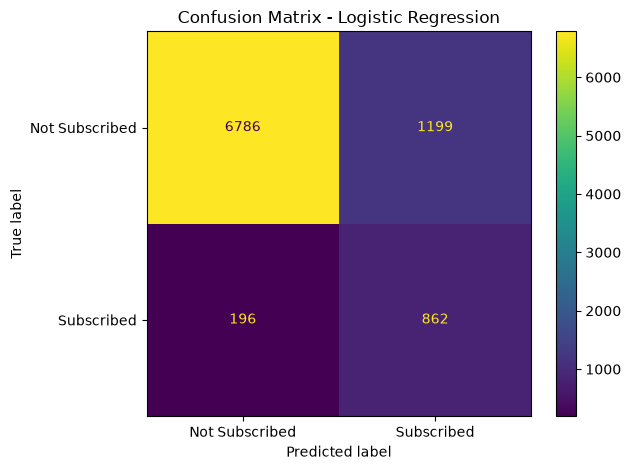

In [21]:
# import the confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["no", "yes"])

# display the confusion matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Subscribed", "Subscribed"]
)

display_matrix.plot()

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()

# Save 
plt.savefig("../charts/confusion_matrix.png", dpi=300, bbox_inches="tight")

plt.show()

##  ROC Curve

The ROC curve shows how well the model distinguishes between subscribers and non-subscribers at different classification thresholds. AUC summarizes this performance.


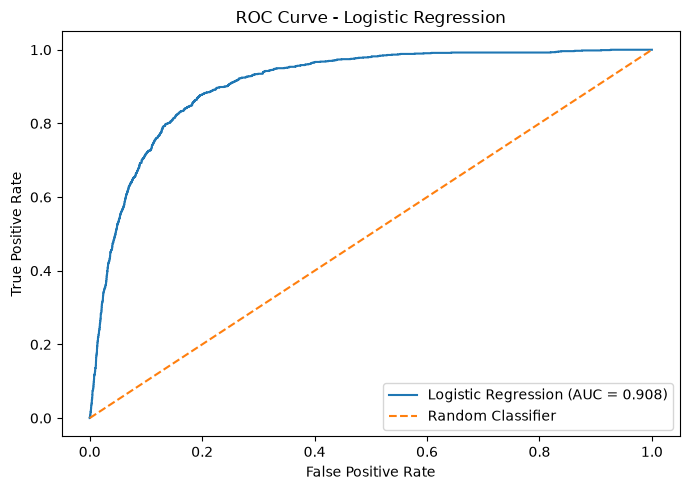

ROC-AUC Score: 0.908


In [22]:
# import ROC evaluation tools
from sklearn.metrics import roc_curve, roc_auc_score

# Get the predicted probability of subscribing
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index("yes")]

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label="yes")
roc_auc = roc_auc_score((y_test == "yes").astype(int), y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()

# Save 
plt.savefig("../charts/roc_curve.png", dpi=300, bbox_inches="tight")

plt.show()

print("ROC-AUC Score:", round(roc_auc, 3))

##  Error Analysis

Error analysis examines incorrect predictions to identify the model's weaknesses and opportunities for improvement.


In [23]:
# create a DataFrame to compare actual and predicted values
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

# identify incorrect predictions
errors = results[results["Actual"] != results["Predicted"]]

# Display error analysis
print("Total test samples:", len(results))
print("Incorrect predictions:", len(errors))
print("Error rate:", round(len(errors) / len(results) * 100, 2), "%")

print("\nTypes of errors:")
print(pd.crosstab(
    errors["Actual"],
    errors["Predicted"],
    rownames=["Actual"],
    colnames=["Predicted"]
))

Total test samples: 9043
Incorrect predictions: 1395
Error rate: 15.43 %

Types of errors:
Predicted   no   yes
Actual              
no           0  1199
yes        196     0


##  Overfitting and Underfitting

Overfitting occurs when a model performs well on training data but poorly on unseen data. Underfitting occurs when a model fails to learn important patterns. Comparing training and testing performance helps identify these issues.


##  Model Improvement

Train a Decision Tree classifier and compare its performance with Logistic Regression using accuracy, precision, recall, and F1-score.


In [24]:
# Import Decision Tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create the Decision Tree pipeline
dt_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=10,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

# Train the Decision Tree
dt_model.fit(X_train, y_train)

# Make predictions
dt_pred = dt_model.predict(X_test)

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Compare both models
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, dt_pred)
    ],
    "Precision (yes)": [
        precision_score(y_test, y_pred, pos_label="yes"),
        precision_score(y_test, dt_pred, pos_label="yes", zero_division=0)
    ],
    "Recall (yes)": [
        recall_score(y_test, y_pred, pos_label="yes"),
        recall_score(y_test, dt_pred, pos_label="yes", zero_division=0)
    ],
    "F1-score (yes)": [
        f1_score(y_test, y_pred, pos_label="yes"),
        f1_score(y_test, dt_pred, pos_label="yes", zero_division=0)
    ]
})

print(model_comparison.round(3))

                 Model  Accuracy  Precision (yes)  Recall (yes)  \
0  Logistic Regression     0.846            0.418         0.815   
1        Decision Tree     0.830            0.393         0.834   

   F1-score (yes)  
0           0.553  
1           0.535  


##  Model Performance Comparison

Compare Logistic Regression and Decision Tree using accuracy, precision, recall, and F1-score to identify the better-performing model.


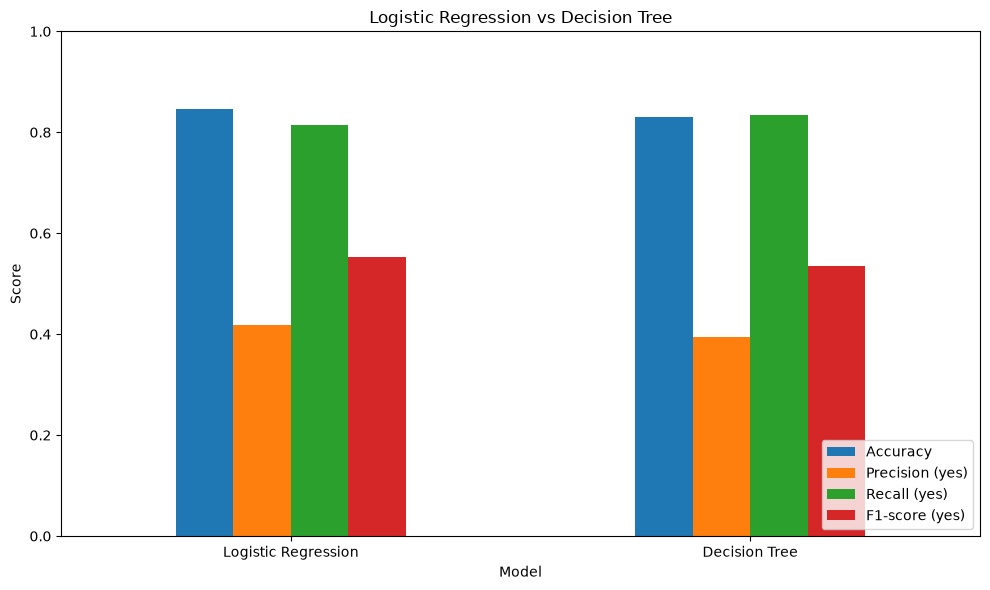

In [25]:
# model performance comparison
metrics = ["Accuracy", "Precision (yes)", "Recall (yes)", "F1-score (yes)"]

model_comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()

# Save the chart
plt.savefig("../charts/model_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

## Final Analysis and Conclusion

Logistic Regression achieved 84.57% accuracy, while Decision Tree achieved 83.00%. Logistic Regression performed better in precision and F1-score, whereas Decision Tree achieved slightly higher recall.

The results show that both models can identify potential subscribers. However, the low precision for the `yes` class indicates that further improvement is needed. Future improvements could include hyperparameter tuning, feature selection, and decision-threshold optimization.


##  Overfitting and Underfitting Check

Compare training and testing accuracy to check how well the model generalizes to unseen data.


In [26]:
# Calculate training and testing accuracy
train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

print(
    "Accuracy Difference:",
    round(abs(train_accuracy - test_accuracy) * 100, 2),
    "%"
)

Training Accuracy: 84.43 %
Testing Accuracy: 84.57 %
Accuracy Difference: 0.15 %


##  Final Conclusion

Logistic Regression achieved 84.57% testing accuracy, with 81.5% recall and a 0.553 F1-score for subscribers. Decision Tree achieved 83.00% accuracy and 83.4% recall.

The training and testing accuracies of Logistic Regression were similar, suggesting reasonable generalization based on accuracy. Further improvements could focus on increasing precision, reducing false positives, and tuning model parameters.
